## Import Library

In [1]:
import os
import numpy as np

import librosa
import librosa.display

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv2D, MaxPooling2D, Dense,
    Dropout, Flatten, BatchNormalization
)
from tensorflow.keras.callbacks import Callback, EarlyStopping


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
DATASET_PATH = "/content/drive/MyDrive/fakeorrealdataset"

X_path = []
y = []

for label in ["real", "fake"]:
    class_path = os.path.join(DATASET_PATH, label)
    for file in os.listdir(class_path):
        if file.endswith(".wav"):
            X_path.append(os.path.join(class_path, file))
            y.append(label)

print("Total data:", len(X_path))

Total data: 100


## EDA

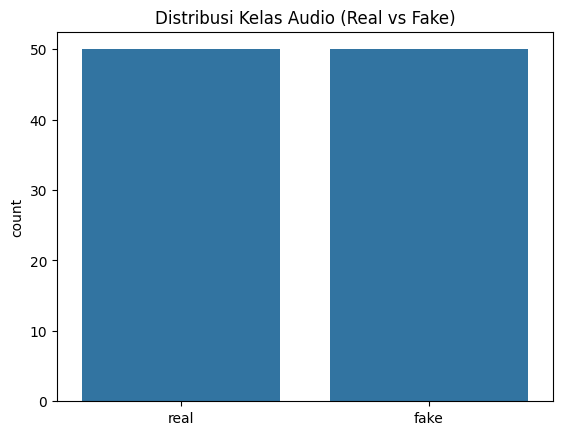

In [4]:
sns.countplot(x=y)
plt.title("Distribusi Kelas Audio (Real vs Fake)")
plt.show()

In [5]:
real_audio = "/content/drive/MyDrive/fakeorrealdataset/real/file1.wav"
fake_audio = "/content/drive/MyDrive/fakeorrealdataset/fake/file1000.mp3"

In [6]:
import IPython.display as ipd

print("Real Audio:")
ipd.Audio(real_audio)

Real Audio:


In [7]:
print("Fake Audio:")
ipd.Audio(fake_audio)

Fake Audio:


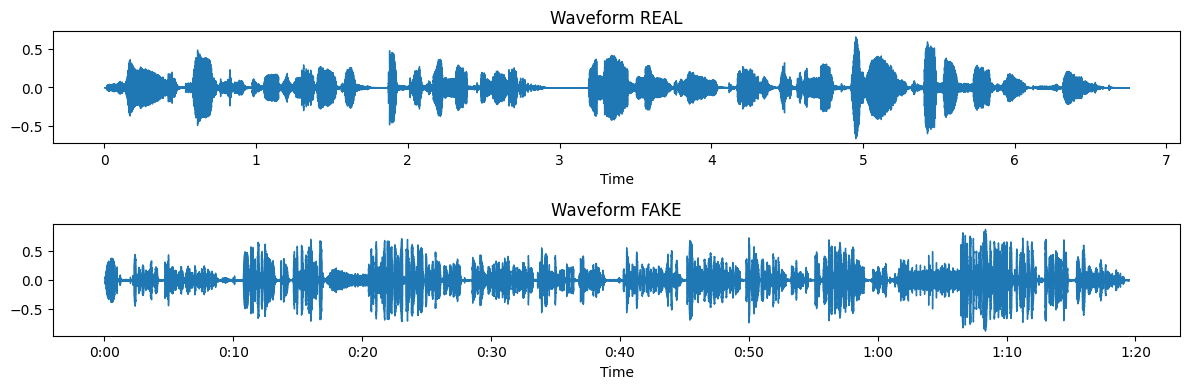

In [8]:
real_audio, sr = librosa.load(X_path[y.index("real")], sr=16000)
fake_audio, _  = librosa.load(X_path[y.index("fake")], sr=16000)

plt.figure(figsize=(12,4))
plt.subplot(2,1,1)
librosa.display.waveshow(real_audio, sr=sr)
plt.title("Waveform REAL")

plt.subplot(2,1,2)
librosa.display.waveshow(fake_audio, sr=sr)
plt.title("Waveform FAKE")
plt.tight_layout()
plt.show()

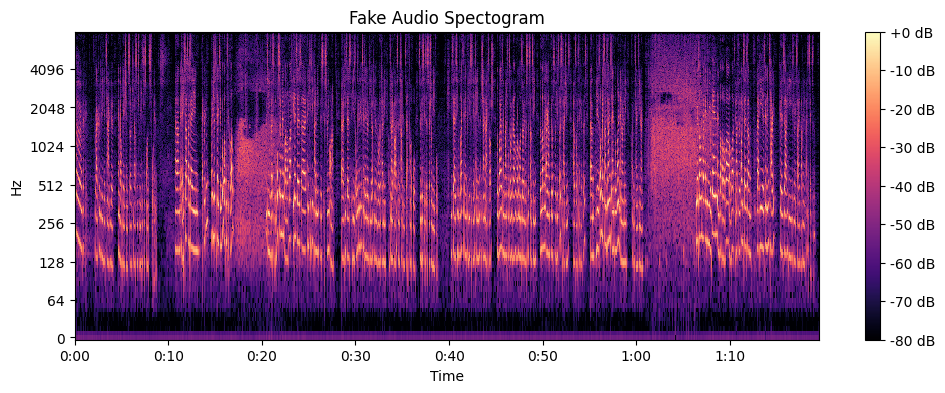

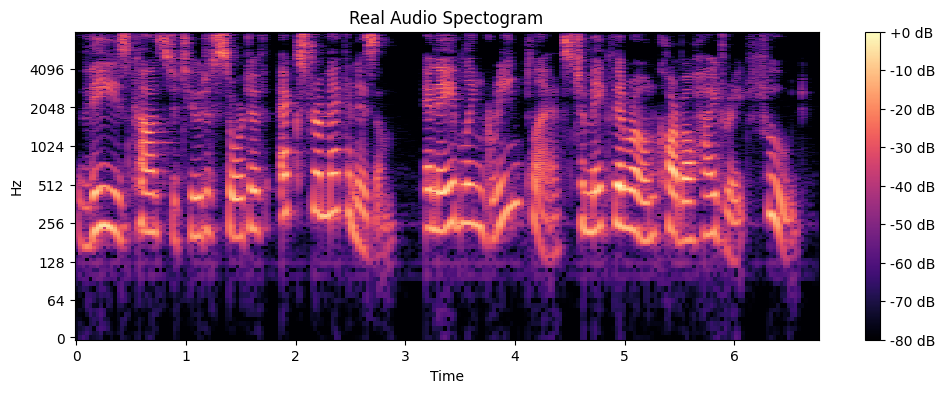

In [10]:
fake_spec = np.abs(librosa.stft(fake_audio))
fake_spec = librosa.amplitude_to_db(fake_spec, ref=np.max)
real_spec = np.abs(librosa.stft(real_audio))
real_spec = librosa.amplitude_to_db(real_spec, ref=np.max)

plt.figure(figsize=(12, 4))
librosa.display.specshow(fake_spec, sr=sr, x_axis="time", y_axis="log")
plt.colorbar(format="%+2.0f dB")
plt.title("Fake Audio Spectogram")
plt.show()

plt.figure(figsize=(12, 4))
librosa.display.specshow(real_spec, sr=sr, x_axis="time", y_axis="log")
plt.colorbar(format="%+2.0f dB")
plt.title("Real Audio Spectogram")
plt.show()

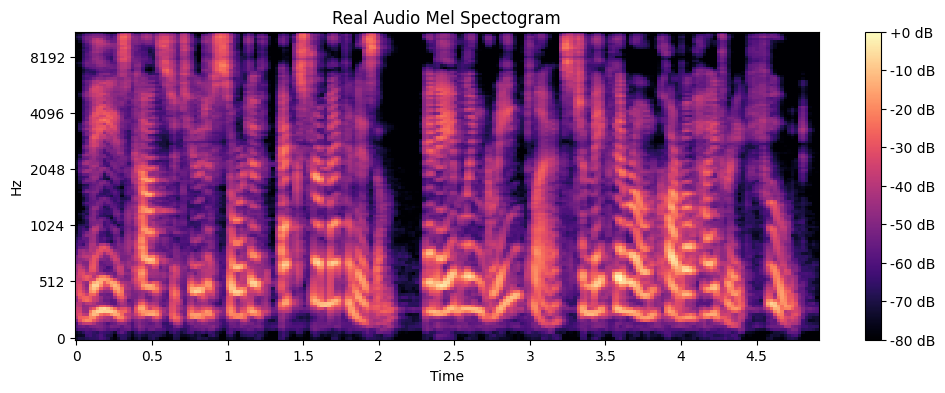

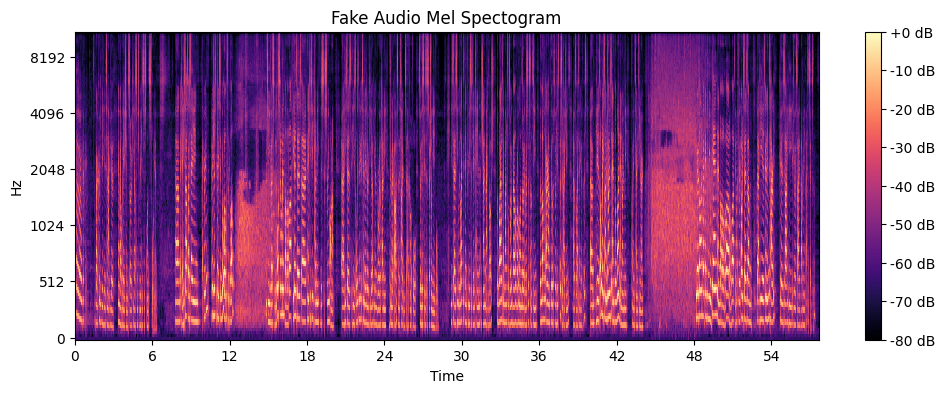

In [12]:
real_mel_spect = librosa.feature.melspectrogram(y=real_audio, sr=sr)
real_mel_spect = librosa.power_to_db(real_mel_spect, ref=np.max)
fake_mel_spect = librosa.feature.melspectrogram(y=fake_audio, sr=sr)
fake_mel_spect = librosa.power_to_db(fake_mel_spect, ref=np.max)

plt.figure(figsize=(12, 4))
librosa.display.specshow(real_mel_spect, y_axis="mel", x_axis="time")
plt.title("Real Audio Mel Spectogram")
plt.colorbar(format="%+2.0f dB")
plt.show()

plt.figure(figsize=(12, 4))
librosa.display.specshow(fake_mel_spect, y_axis="mel", x_axis="time")
plt.title("Fake Audio Mel Spectogram")
plt.colorbar(format="%+2.0f dB")
plt.show()

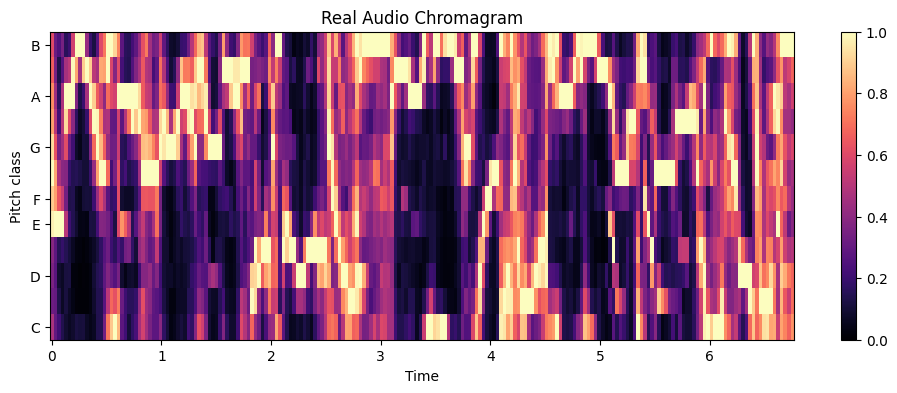

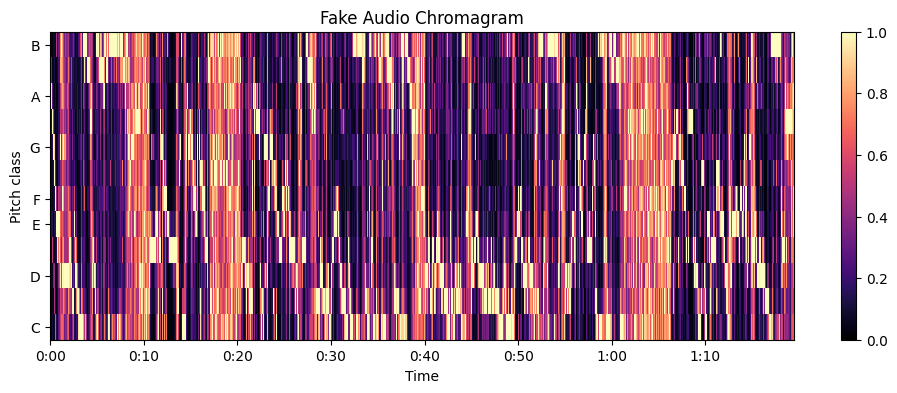

In [14]:
fake_chroma = librosa.feature.chroma_cqt(y=fake_audio, sr=sr, bins_per_octave=36)
real_chroma = librosa.feature.chroma_cqt(y=real_audio, sr=sr, bins_per_octave=36)

plt.figure(figsize=(12, 4))
librosa.display.specshow(real_chroma, sr=sr, x_axis="time", y_axis="chroma", vmin=0, vmax=1)
plt.colorbar()
plt.title("Real Audio Chromagram")
plt.show()

plt.figure(figsize=(12, 4))
librosa.display.specshow(fake_chroma, sr=sr, x_axis="time", y_axis="chroma", vmin=0, vmax=1)
plt.colorbar()
plt.title("Fake Audio Chromagram")
plt.show()

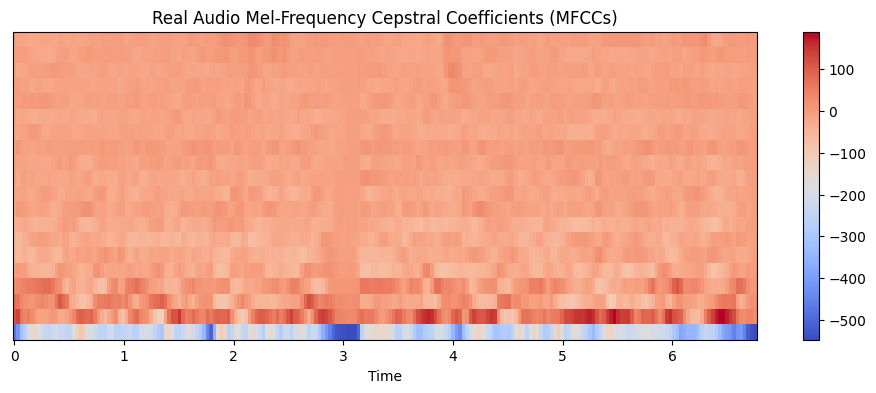

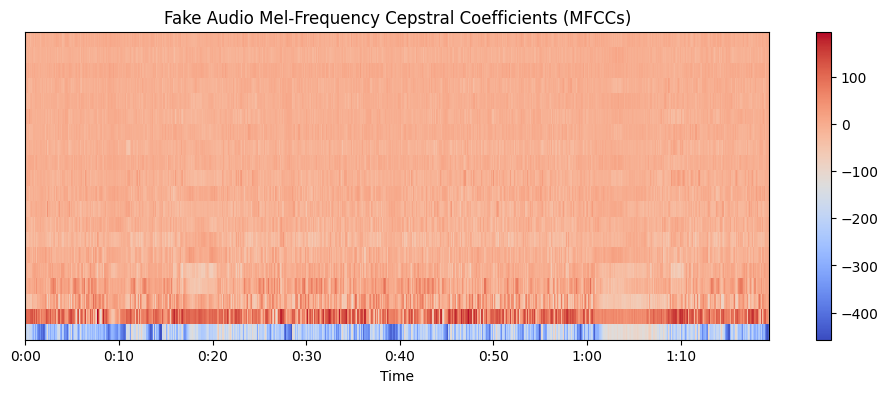

In [16]:
fake_mfccs = librosa.feature.mfcc(y=fake_audio, sr=sr)
real_mfccs = librosa.feature.mfcc(y=real_audio, sr=sr)

plt.figure(figsize=(12, 4))
librosa.display.specshow(real_mfccs, sr=sr, x_axis="time")
plt.colorbar()
plt.title("Real Audio Mel-Frequency Cepstral Coefficients (MFCCs)")
plt.show()

plt.figure(figsize=(12, 4))
librosa.display.specshow(fake_mfccs, sr=sr, x_axis="time")
plt.colorbar()
plt.title("Fake Audio Mel-Frequency Cepstral Coefficients (MFCCs)")
plt.show()

## Data Preprocessing

### Extract MFCC

In [17]:
SR = 16000
N_MFCC = 40
MAX_LEN = 130

def extract_mfcc(file_path):
    y, _ = librosa.load(file_path, sr=SR)
    mfcc = librosa.feature.mfcc(y=y, sr=SR, n_mfcc=N_MFCC)

    if mfcc.shape[1] < MAX_LEN:
        pad = MAX_LEN - mfcc.shape[1]
        mfcc = np.pad(mfcc, ((0,0),(0,pad)))
    else:
        mfcc = mfcc[:, :MAX_LEN]

    return mfcc

In [18]:
X_mfcc = np.array([extract_mfcc(f) for f in X_path])
print("MFCC shape:", X_mfcc.shape)

MFCC shape: (100, 40, 130)


## Feature Engineering

### Encode Label

In [19]:
y_bin = np.array([0 if label == "real" else 1 for label in y])

X_train, X_test, y_train, y_test = train_test_split(
    X_mfcc, y_bin,
    test_size=0.2,
    random_state=42,
    stratify=y_bin
)

### Normalisasi MFCC

In [20]:
scaler = StandardScaler()

X_train = scaler.fit_transform(
    X_train.reshape(len(X_train), -1)
).reshape(X_train.shape)

X_test = scaler.transform(
    X_test.reshape(len(X_test), -1)
).reshape(X_test.shape)

### Tambah Channel

In [21]:
X_train = X_train[..., np.newaxis]
X_test  = X_test[..., np.newaxis]

## Modelling

In [22]:
class StopAtValAccuracy(Callback):
    def __init__(self, target=0.90):
        super().__init__()
        self.target = target

    def on_epoch_end(self, epoch, logs=None):
        if logs.get("val_accuracy") >= self.target:
            print(f"\nVal Accuracy {logs['val_accuracy']:.2%} tercapai. Stop training.")
            self.model.stop_training = True

In [23]:
model = Sequential([
    Conv2D(32, (3,3), activation='relu',
           input_shape=(N_MFCC, MAX_LEN, 1)),
    BatchNormalization(),
    MaxPooling2D((2,2)),
    Dropout(0.3),

    Conv2D(64, (3,3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D((2,2)),
    Dropout(0.3),

    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.4),

    Dense(1, activation='sigmoid')  # Binary
])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [24]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 38, 128, 32)    │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 38, 128, 32)    │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 19, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 19, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 17, 62, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 17, 62, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 31, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 31, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 15872)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     2,031,744 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,051,073 (7.82 MB)

 Trainable params: 2,050,881 (7.82 MB)

 Non-trainable params: 192 (768.00 B)

## Training

In [25]:
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_test, y_test),
    epochs=100,
    batch_size=16,
    callbacks=[
        StopAtValAccuracy(0.90),
        EarlyStopping(
            monitor='val_loss',
            patience=7,
            restore_best_weights=True
        )
    ]
)

Epoch 1/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 7s 288ms/step - accuracy: 0.6590 - loss: 1.1893 - val_accuracy: 0.7500 - val_loss: 0.4505
Epoch 2/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 214ms/step - accuracy: 0.8321 - loss: 1.9820 - val_accuracy: 0.7500 - val_loss: 0.9046
Epoch 3/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 205ms/step - accuracy: 0.8484 - loss: 3.3565 - val_accuracy: 0.7500 - val_loss: 0.3889
Epoch 4/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 213ms/step - accuracy: 0.9380 - loss: 0.1284 - val_accuracy: 0.9000 - val_loss: 0.1686
Epoch 5/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 203ms/step - accuracy: 0.9660 - loss: 0.2193 - val_accuracy: 0.9000 - val_loss: 0.1759
Epoch 6/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 203ms/step - accuracy: 0.9741 - loss: 0.0543 - val_accuracy: 0.8500 - val_loss: 0.2693
Epoch 7/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 191ms/step - accuracy: 0.9891 - loss: 0.0119 - val_accuracy: 0.8500 - val_loss: 0.2073
Epoch 8/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 228ms/step - accuracy: 0.9815 - loss: 0.0382
Val Accuracy 95.00% tercap

## Evaluation

In [26]:
loss, acc = model.evaluate(X_test, y_test)
print(f"Test Accuracy: {acc:.2%}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step - accuracy: 0.9500 - loss: 0.0626
Test Accuracy: 95.00%


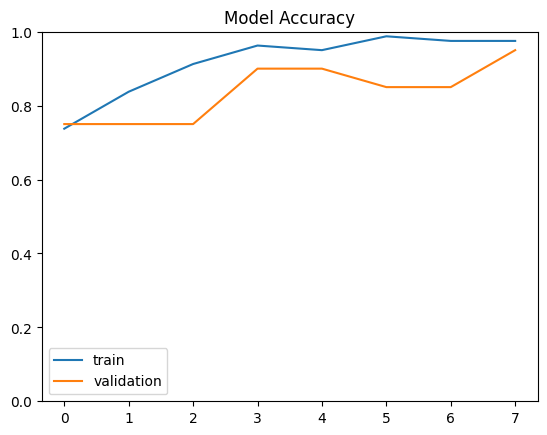

In [29]:
plt.figure()
plt.title("Model Accuracy")
plt.plot(history.history["accuracy"], label="train")
plt.plot(history.history["val_accuracy"], label="validation")
plt.legend()
plt.ylim([0, 1])
plt.show()

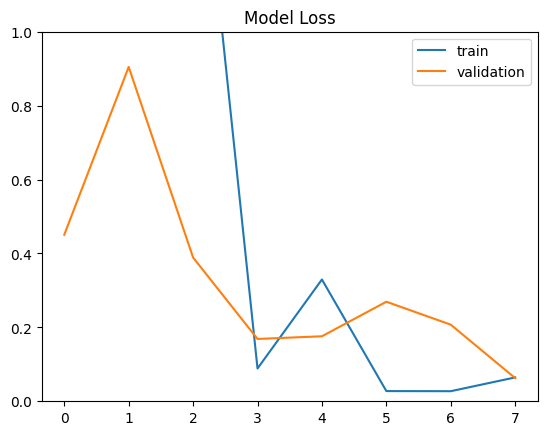

In [30]:
plt.figure()
plt.title("Model Loss")
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="validation")
plt.legend()
plt.ylim([0, 1])
plt.show()

In [27]:
y_pred = (model.predict(X_test) > 0.5).astype(int)

print(classification_report(
    y_test, y_pred,
    target_names=["Real", "Fake"]
))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 218ms/step
              precision    recall  f1-score   support

        Real       0.91      1.00      0.95        10
        Fake       1.00      0.90      0.95        10

    accuracy                           0.95        20
   macro avg       0.95      0.95      0.95        20
weighted avg       0.95      0.95      0.95        20



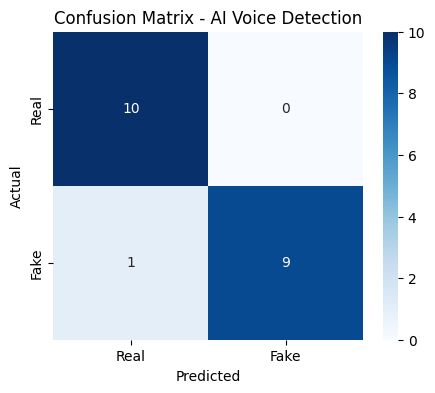

In [28]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5,4))
sns.heatmap(
    cm, annot=True, fmt='d',
    xticklabels=["Real", "Fake"],
    yticklabels=["Real", "Fake"],
    cmap="Blues"
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - AI Voice Detection")
plt.show()

In [31]:
model.save("deepfake_audio_model.h5")

In [32]:
import joblib

joblib.dump(scaler, "mfcc_scaler.pkl")

['mfcc_scaler.pkl']